<a href="https://colab.research.google.com/github/NisalJayaweera/EN3160-Fitting-and-Alignment/blob/main/notebooks/Q3_Homography_GitHub_Images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3160 Assignment 02 — Question 3: Planar Homography and Image Compositing

**Image pair 1:** University of Moratuwa crest projected onto the pale front fascia of a University of Moratuwa building photograph.

This notebook uses four corresponding corner points to estimate a projective transformation, warps an RGBA crest into the target quadrilateral, and alpha-composites it with the photograph. The logo retains its transparent background. The chosen quadrilateral lies to the left of the building name to avoid obscuring the lettering. The result is a *digital mock-up*, not a claim that the crest is physically mounted there.

**Assignment coverage:** This is **one** of the required two image pairs. A second independent image pair is still required for full Q3 compliance.

**Scope:** This notebook completes the first of the two image-pair demonstrations requested in Q3; a second pair is still required for the full assignment.

## 1. Inputs and reproducibility

The source photographs are versioned in the [assignment GitHub repository](https://github.com/NisalJayaweera/EN3160-Fitting-and-Alignment/tree/main/images). This notebook **downloads the two PNG files from GitHub automatically**, so it runs in Google Colab or a local Jupyter environment without manual uploads. The image bytes are cached in a local `images/` directory. If an existing file is corrupt, it is downloaded again. Internet access is required on the first run.

The background is decoded in BGR, while the crest is decoded with its alpha (transparency) channel intact.

Background (H, W, C): (813, 1535, 3)
Logo (H, W, C): (325, 306, 4)


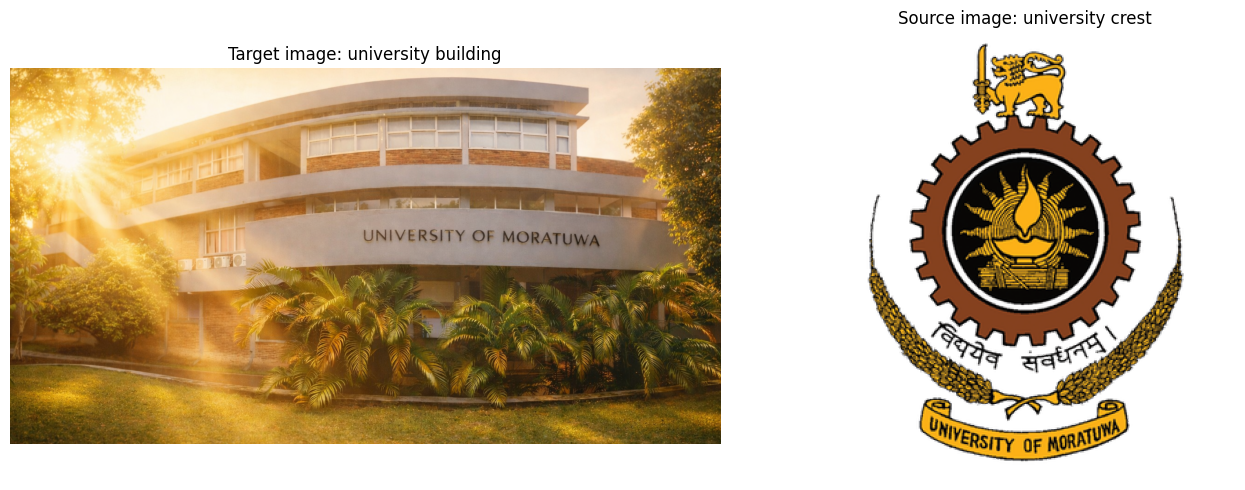

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
IMAGE_DIR = ROOT / "images"
OUTPUT_DIR = ROOT / "results"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

GITHUB_RAW = ("https://raw.githubusercontent.com/"
              "NisalJayaweera/EN3160-Fitting-and-Alignment/main/images/")
BACKGROUND_PATH = IMAGE_DIR / "bgmain-mldlys04.png"
LOGO_PATH = IMAGE_DIR / "University_of_Moratuwa_logo.png"

def ensure_github_png(path: Path, flags: int):
    """Read cached PNG, or download the original from GitHub if absent/invalid."""
    img = cv2.imread(str(path), flags) if path.is_file() else None
    if img is not None:
        print(f"Using cached image: {path}")
        return img
    url = GITHUB_RAW + path.name
    print(f"Downloading from GitHub: {url}")
    try:
        req = Request(url, headers={"User-Agent": "EN3160-assignment-notebook"})
        with urlopen(req, timeout=45) as response:
            data = response.read()
    except Exception as exc:
        raise RuntimeError(f"Unable to download {path.name} from {url}: {exc}") from exc
    decoded = cv2.imdecode(np.frombuffer(data, dtype=np.uint8), flags)
    if decoded is None:
        raise ValueError(f"Downloaded data is not a valid image: {url}")
    path.write_bytes(data)
    return decoded

background = ensure_github_png(BACKGROUND_PATH, cv2.IMREAD_COLOR)
logo = ensure_github_png(LOGO_PATH, cv2.IMREAD_UNCHANGED)
if logo.ndim != 3 or logo.shape[2] != 4:
    raise ValueError("The source logo must be an RGBA PNG with transparency.")
print("Background (H, W, C):", background.shape)
print("Logo (H, W, C):", logo.shape)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
axs[0].imshow(cv2.cvtColor(background, cv2.COLOR_BGR2RGB))
axs[0].set_title("Target image: university building")
axs[1].imshow(cv2.cvtColor(logo, cv2.COLOR_BGRA2RGBA))
axs[1].set_title("Source image: university crest")
for ax in axs: ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Four-point correspondence

The source points are the four corners of the logo raster. The destination points are manually selected points on the approximately planar front fascia, in the same order: top-left, top-right, bottom-right, bottom-left. These pixel coordinates refer specifically to the supplied **1535 × 813** photograph. If the image changes resolution, reselect the points.

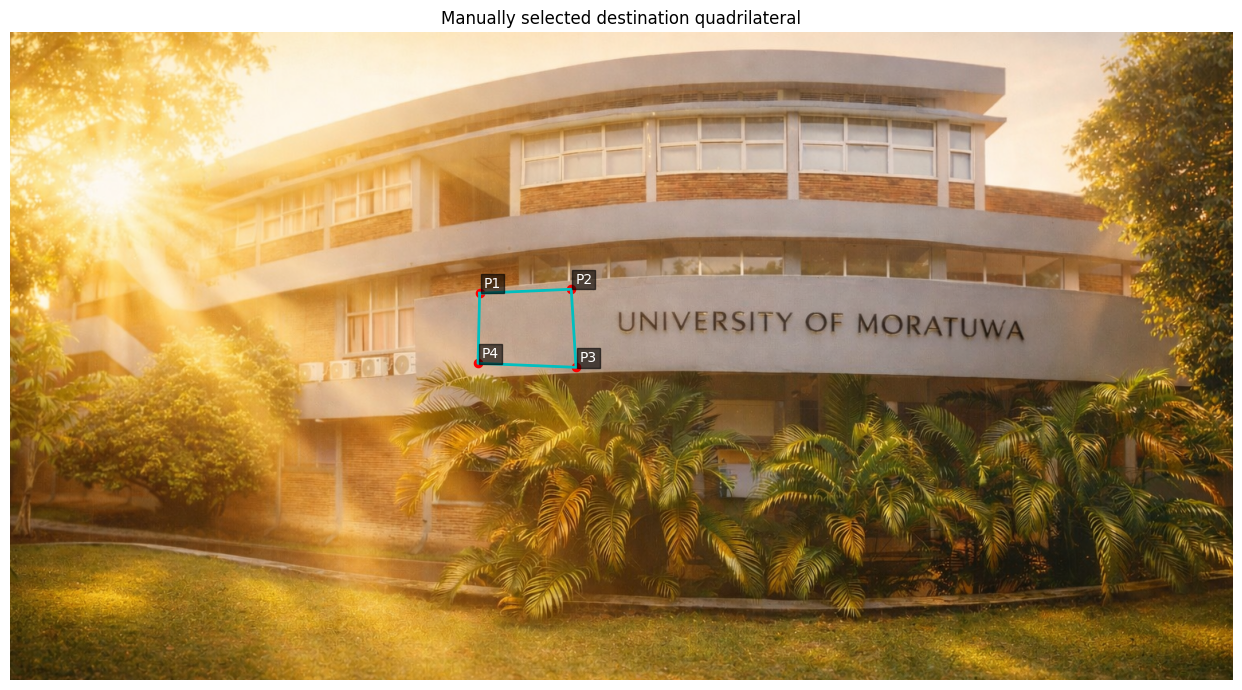

Source corners:
 [[  0.   0.]
 [305.   0.]
 [305. 324.]
 [  0. 324.]]
Destination corners:
 [[589. 327.]
 [704. 322.]
 [710. 420.]
 [587. 415.]]


In [2]:
h, w = logo.shape[:2]
src_pts = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
dst_pts = np.float32([[589, 327], [704, 322], [710, 420], [587, 415]])

preview = cv2.cvtColor(background.copy(), cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots(figsize=(15, 7))
ax.imshow(preview)
polygon = np.vstack([dst_pts, dst_pts[0]])
ax.plot(polygon[:, 0], polygon[:, 1], 'c-', linewidth=2)
for i, (x, y) in enumerate(dst_pts):
    ax.scatter(x, y, c='red', s=35)
    ax.text(x + 5, y - 7, f'P{i+1}', color='white', fontsize=10, bbox={'facecolor':'black','alpha':0.6,'pad':2})
ax.set_title('Manually selected destination quadrilateral')
ax.axis('off'); plt.tight_layout(); plt.show()
print('Source corners:\n', src_pts)
print('Destination corners:\n', dst_pts)

## 3. Homography estimation

A homography maps a point $(x,y)$ on the source plane to $(x',y')$ on the target plane:

$$\lambda\begin{bmatrix}x'\\y'\\1\end{bmatrix}=H\begin{bmatrix}x\\y\\1\end{bmatrix},\qquad H\in\mathbb{R}^{3\times3}.$$

There are eight independent degrees of freedom because the matrix is defined up to scale. Four non-collinear point correspondences determine a homography. `cv2.getPerspectiveTransform` estimates it directly; RANSAC is unnecessary when there are exactly four manually selected correspondences. The reprojection check below tests whether the four source corners map to the intended target corners.

In [3]:
H = cv2.getPerspectiveTransform(src_pts, dst_pts)
projected = cv2.perspectiveTransform(src_pts.reshape(-1, 1, 2), H).reshape(-1, 2)
corner_error = np.linalg.norm(projected - dst_pts, axis=1)
print('Homography H:\n', H)
print('Corner reprojection errors (pixels):', np.round(corner_error, 6))
assert np.all(np.isfinite(H)) and np.max(corner_error) < 1e-2


Homography H:
 [[ 1.48609884e-01 -1.15262274e-01  5.89000000e+02]
 [-1.20878462e-01  1.94480381e-01  3.27000000e+02]
 [-3.24487637e-04 -1.85842307e-04  1.00000000e+00]]
Corner reprojection errors (pixels): [0. 0. 0. 0.]


## 4. Perspective warp and alpha compositing

The RGBA logo is warped into the background coordinate system using `cv2.warpPerspective`. Its alpha channel is warped together with its RGB channels, so transparent logo pixels do not produce an opaque rectangular background. Bilinear interpolation smooths resampling artifacts. The compositing equation is $I_{out}=lpha I_{logo}+(1-lpha)I_{background}$. A configurable opacity of 0.90 leaves a little of the wall texture visible; it is an artistic choice rather than a physical lighting model.

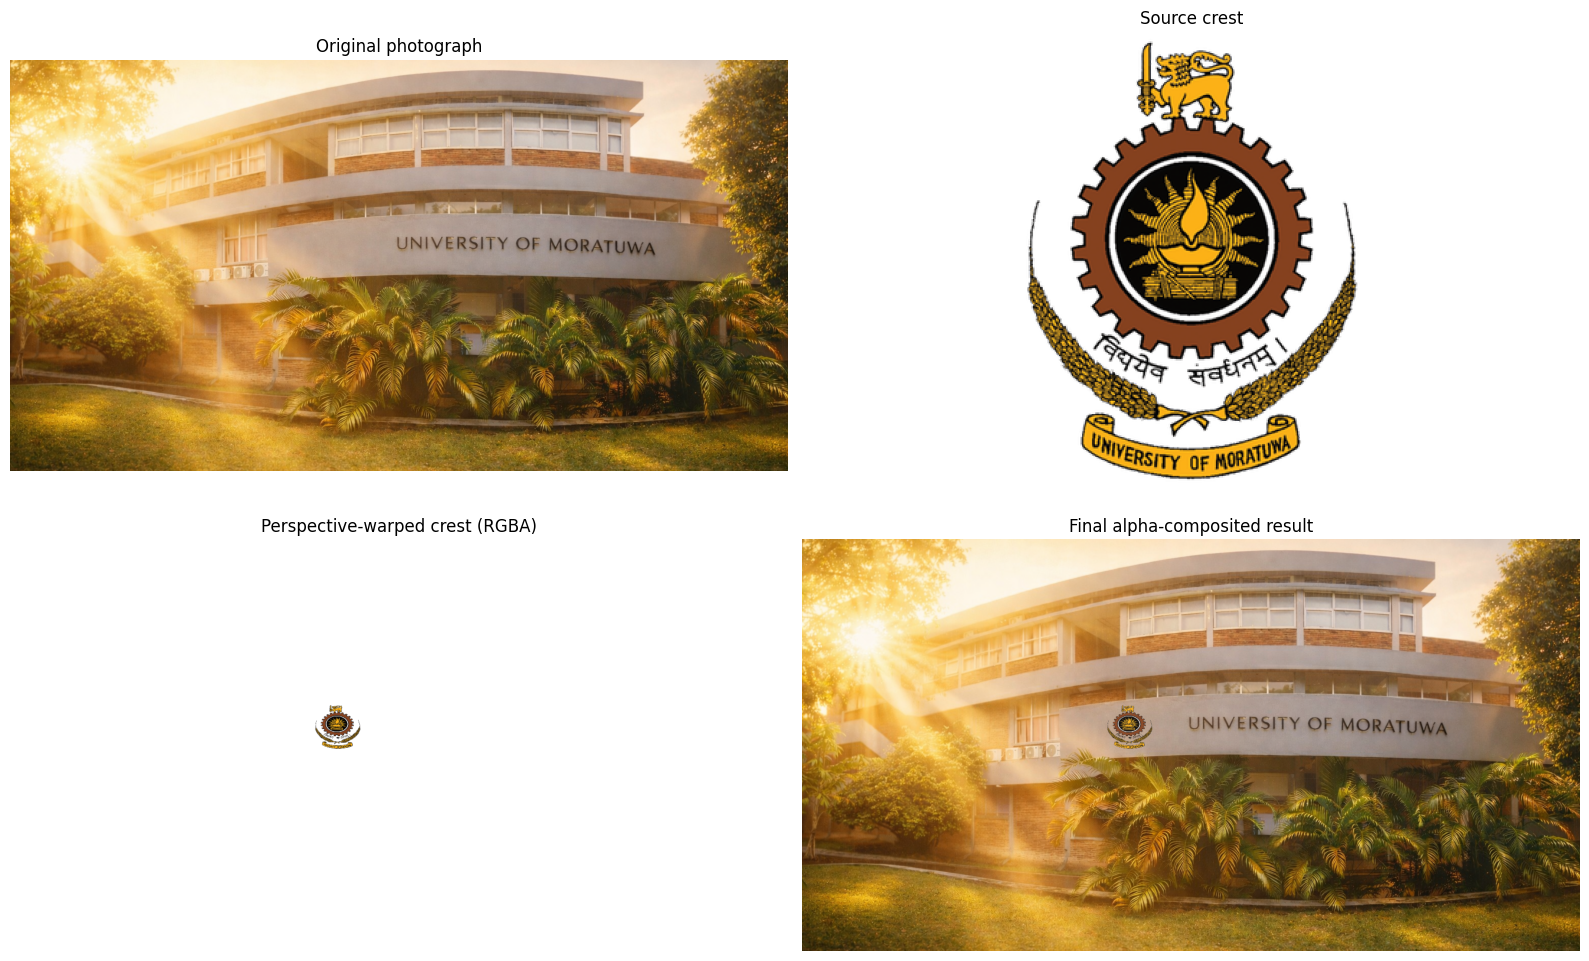

In [4]:
bh, bw = background.shape[:2]
warped = cv2.warpPerspective(logo, H, (bw, bh), flags=cv2.INTER_LINEAR,
                             borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0, 0))
opacity = 0.90
alpha = (warped[:, :, 3:4].astype(np.float32) / 255.0) * opacity
composite = (alpha * warped[:, :, :3].astype(np.float32)
             + (1 - alpha) * background.astype(np.float32))
composite = np.clip(composite, 0, 255).astype(np.uint8)
cv2.imwrite(str(OUTPUT_DIR / 'q3_pair1_composite.png'), composite)
cv2.imwrite(str(OUTPUT_DIR / 'q3_pair1_warped_logo.png'), warped)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes[0, 0].imshow(cv2.cvtColor(background, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title('Original photograph')
axes[0, 1].imshow(cv2.cvtColor(logo, cv2.COLOR_BGRA2RGBA)); axes[0, 1].set_title('Source crest')
axes[1, 0].imshow(cv2.cvtColor(warped, cv2.COLOR_BGRA2RGBA)); axes[1, 0].set_title('Perspective-warped crest (RGBA)')
axes[1, 1].imshow(cv2.cvtColor(composite, cv2.COLOR_BGR2RGB)); axes[1, 1].set_title('Final alpha-composited result')
for ax in axes.flat: ax.axis('off')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'q3_pair1_comparison.png', dpi=160); plt.show()

## 5. Discussion

The crest is positioned on the front fascia because it offers a comparatively smooth, near-planar region and avoids the existing building lettering. Four manually specified point correspondences capture the trapezoidal distortion produced by the viewpoint. The near-zero corner reprojection errors confirm that the estimated homography matches those four correspondences; they **do not** establish that the selected surface is perfectly planar or that the composition looks photorealistic.

The transparent crest is composited without a solid rectangular background. The resulting overlay demonstrates geometric alignment, but it does not model cast shadows, wall reflectance, occlusion by foreground objects, or changing illumination. Moreover, the fascia is visibly **curved** rather than perfectly planar: a single homography can only approximate its projection locally. For a more realistic result, a piecewise planar warp or surface-aware deformation would be needed.

**Image choice rationale:** Both images represent the same university, making the virtual signage a contextually relevant demonstration. The source has a transparent background, which makes the blending step easier to inspect.

**Scope:** This notebook documents image pair 1 only. Repeat the workflow with a second source/target pair to satisfy the assignment's requirement for a couple of image pairs.

**Assignment completeness:** This experiment demonstrates one source–target pair. Question 3 explicitly requests a couple of image pairs, so a second experiment must be added before final submission.